In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [2]:
df = pd.read_csv('train.csv')
df.head(10)

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500
5,5,Audi,A6 2.0T Sport,2018,40950,Gasoline,252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,A/T,White,–,None reported,Yes,29950
6,6,Audi,A8 L 3.0T,2016,62200,Gasoline,333.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,Black,Black,None reported,Yes,28500
7,7,Chevrolet,Silverado 1500 1LZ,2016,102604,E85 Flex Fuel,355.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,White,Gray,None reported,Yes,12500
8,8,Ford,F-150 XLT,2020,38352,Gasoline,2.7L V6 24V PDI DOHC Twin Turbo,10-Speed Automatic,Snowflake White Pearl Metallic,Black,None reported,Yes,62890
9,9,BMW,M4 Base,2015,74850,Gasoline,425.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,Transmission w/Dual Shift Mode,Black,Blue,None reported,Yes,4000


In [3]:
df.tail(10)

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
188523,188523,BMW,328 i,2011,239000,Gasoline,230.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,6-Speed A/T,Black,Black,None reported,Yes,8000
188524,188524,Chevrolet,Camaro 1LT,2019,59692,Gasoline,335.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,10-Speed A/T,Red,Black,At least 1 accident or damage reported,Yes,33600
188525,188525,Audi,A4 2.0T Premium quattro,2011,121886,Gasoline,211.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,8-Speed A/T,Gray,Black,None reported,Yes,6000
188526,188526,GMC,Yukon XL Denali,2016,89291,Gasoline,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,8-Speed A/T,Red,Black,At least 1 accident or damage reported,Yes,24700
188527,188527,Chevrolet,Camaro Z28,1999,110000,Gasoline,310.0HP 5.7L 8 Cylinder Engine Gasoline Fuel,A/T,White,Gray,None reported,Yes,14500
188528,188528,Cadillac,Escalade ESV Platinum,2017,49000,Gasoline,420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,White,Beige,None reported,Yes,27500
188529,188529,Mercedes-Benz,AMG C 43 AMG C 43 4MATIC,2018,28600,Gasoline,385.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,8-Speed A/T,White,Black,At least 1 accident or damage reported,Yes,30000
188530,188530,Mercedes-Benz,AMG GLC 63 Base 4MATIC,2021,13650,Gasoline,469.0HP 4.0L 8 Cylinder Engine Gasoline Fuel,7-Speed A/T,White,Black,None reported,Yes,86900
188531,188531,Audi,S5 3.0T Prestige,2022,13895,Gasoline,3.0L,1-Speed Automatic,Daytona Gray Pearl Effect,Black,None reported,NaN,84900
188532,188532,Porsche,Macan Base,2016,59500,Gasoline,252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,White,Black,None reported,Yes,28995


In [4]:
df.isna().sum()

id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
dtype: int64

In [5]:
df.shape

(188533, 13)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,188533.0,94266.000000,54424.933488,0.0,47133.0,94266.0,141399.0,188532.0
model_year,188533.0,2015.829998,5.660967,1974.0,2013.0,2017.0,2020.0,2024.0
milage,188533.0,65705.295174,49798.158076,100.0,24115.0,57785.0,95400.0,405000.0
price,188533.0,43878.016178,78819.522254,2000.0,17000.0,30825.0,49900.0,2954083.0


In [8]:
print(df.nlargest(10, 'price')[['brand','model','model_year','milage','price']])

               brand                                       model  model_year  \
220             Ford                                   F-150 XLT        2021   
1880        Chrysler                                   300C Base        2003   
13838         Toyota                               Highlander SE        2014   
14693        Hyundai                                Santa Fe SEL        2022   
16034  Mercedes-Benz                     SL-Class SL500 Roadster        2005   
18946           Audi                                     S4 Base        2004   
21814            RAM                                1500 Laramie        2022   
36615           Ford                  Excursion Limited Ultimate        2002   
42177           Ford                                  Mustang GT        2005   
42219           Land  Rover Range Rover 3.0L V6 Supercharged HSE        2021   

       milage    price  
220     26315  2954083  
1880    55900  2954083  
13838   85000  2954083  
14693   13865  2954

In [9]:
print(df.nsmallest(10, 'price')[['brand','model','model_year','milage','price']])

               brand                model  model_year  milage  price
758          Pontiac    Firebird Trans Am        2001  150000   2000
3681          Toyota    Camry Hybrid Base        2003  155000   2000
4781          Toyota     Camry Solara SLE        2001   73690   2000
11146      Chevrolet       Monte Carlo SS        2001   64776   2000
12655  Mercedes-Benz     SLK-Class SLK320        2003  107000   2000
17482            GMC        Terrain SLT-1        2003   90000   2000
17849          Acura          MDX Touring        2007  116000   2000
18918           Ford  Dakota SLT Quad Cab        2002  138000   2000
19305     Mitsubishi    Eclipse Spyder GT        2003  120000   2000
22415        Lincoln   Town Car Signature        2003  120000   2000


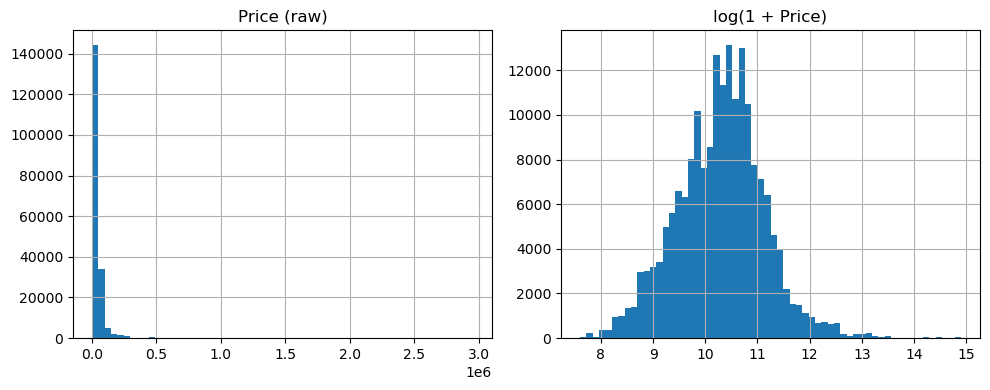

In [10]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
df['price'].hist(bins=60)
plt.title("Price (raw)")
plt.subplot(1,2,2)
np.log1p(df['price']).hist(bins=60)
plt.title("log(1 + Price)")
plt.tight_layout()
plt.show()

In [11]:
print("NUM BRANDS:", df['brand'].nunique())
print(df['brand'].value_counts().head(15))
print()
print("BRANDS WITH <5 ROWS:", (df['brand'].value_counts() < 5).sum())

NUM BRANDS: 57
brand
Ford             23088
Mercedes-Benz    19172
BMW              17028
Chevrolet        16335
Audi             10887
Porsche          10612
Land              9525
Toyota            8850
Lexus             8643
Jeep              6474
Cadillac          4674
RAM               4249
Nissan            3930
Tesla             3738
INFINITI          3276
Name: count, dtype: int64

BRANDS WITH <5 ROWS: 2


In [12]:
def fixed_brand_names(row):
    b = str(row['brand']).strip()
    m = str(row['model']).strip()
    if b=='Land' and m.startswith("Rover"): return "Land Rover"
    if b=='Alfa' and m.startswith("Romeo"): return "Alfa Romeo"
    if b=="Aston" and m.startswith("Martin"): return "Aston Martin"
    if b=="Rolls" and m.startswith("Royce"): return "Rolls-Royce"
    return b
df['brand'] = df.apply(fixed_brand_names,axis=1)

In [13]:
def extract_hp_fixed(s):
    match = re.search(r'(\d+\.?\d*)HP', str(s))
    return float(match.group(1)) if match else np.nan

def extract_liters(s):
    match = re.search(r'(\d+\.\d+)L', str(s))
    return float(match.group(1)) if match else np.nan

def extract_cyl(s):
    match = re.search(r'(\d+)\s*Cylinder', str(s))
    return int(match.group(1)) if match else np.nan
df['horsepower'] = df['engine'].apply(extract_hp_fixed)
df['displacement_L'] = df['engine'].apply(extract_liters)
df['cylinders'] = df['engine'].apply(extract_cyl)

In [14]:
def clean_fuel(row):
    engine_text = str(row['engine']).lower()
    if 'electric' in engine_text and 'gasoline' not in engine_text: return 'Electric'
    if 'plug-in' in engine_text: return 'Plug-In Hybrid'
    if 'hybrid' in engine_text: return 'Hybrid'
    if 'diesel' in engine_text: return 'Diesel'
    if 'flex' in engine_text: return 'Flex Fuel'
    if 'gasoline' in engine_text: return 'Gasoline'
    orig_fuel = str(row['fuel_type']).strip()
    return orig_fuel if orig_fuel not in ['nan', ''] else 'Unknown' 
df['fuel_type']=df.apply(clean_fuel,axis=1)

In [15]:
def clean_transmission(s):
    s = str(s).lower()
    if 'm/t' in s or 'manual' in s: return 'Manual'
    if 'cvt' in s: return 'CVT'
    if 'dual' in s: return 'Dual-Clutch'
    return 'Automatic'

df['trans_type'] = df['transmission'].apply(clean_transmission)

In [16]:
df['had_accident'] = df['accident'].astype(str).str.lower().str.contains('accident').astype(int)
def fix_title(s):
    s = str(s).strip().lower()
    if s == 'yes': return 1
    if pd.isna(s) or s == 'nan': return np.nan
    return 0
df['clean_title_flag'] = df['clean_title'].apply(fix_title)
df['clean_title_flag'] = df['clean_title_flag'].fillna(0)

In [17]:
CURRENT_YEAR = 2024 
df['age'] = CURRENT_YEAR - df['model_year']
df['milage_per_year'] = df['milage'] / df['age'].clip(lower=1)

In [18]:
upper_limit = df['price'].quantile(0.99)
df['price'] = df['price'].clip(upper=upper_limit)
print(f"Capped max price at: ${upper_limit:.2f}")

Capped max price at: $259500.00


In [19]:
df['log_price'] = np.log1p(df['price'])

In [20]:
print(df[['brand', 'horsepower', 'displacement_L', 'fuel_type', 'age', 'log_price']].head())

           brand  horsepower  displacement_L  fuel_type  age  log_price
0           MINI       172.0             1.6   Gasoline   17   8.343078
1        Lincoln       252.0             3.9   Gasoline   22   8.517193
2      Chevrolet       320.0             5.3  Flex Fuel   22   9.539716
3        Genesis       420.0             5.0   Gasoline    7  10.714440
4  Mercedes-Benz       208.0             2.0   Gasoline    3  11.487618


In [21]:
# Check that horsepower now has real HP values (should be > 100, not 1.6 or 3.0)
print(df[['engine', 'horsepower', 'displacement_L']].head(10))

# Check that clean_title_flag is 0 or 1, and fuel_type is clean
print(df[['clean_title', 'clean_title_flag', 'fuel_type']].head(10))

                                              engine  horsepower  \
0       172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel       172.0   
1       252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel       252.0   
2  320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...       320.0   
3       420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel       420.0   
4       208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel       208.0   
5       252.0HP 2.0L 4 Cylinder Engine Gasoline Fuel       252.0   
6      333.0HP 3.0L V6 Cylinder Engine Gasoline Fuel       333.0   
7  355.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...       355.0   
8                    2.7L V6 24V PDI DOHC Twin Turbo         NaN   
9  425.0HP 3.0L Straight 6 Cylinder Engine Gasoli...       425.0   

   displacement_L  
0             1.6  
1             3.9  
2             5.3  
3             5.0  
4             2.0  
5             2.0  
6             3.0  
7             5.3  
8             2.7  
9             3.0  
  clean_title  clean_title_flag

In [22]:
df.head()

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,...,price,horsepower,displacement_L,cylinders,trans_type,had_accident,clean_title_flag,age,milage_per_year,log_price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,...,4200,172.0,1.6,4.0,Automatic,0,1.0,17,12529.411765,8.343078
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,...,4999,252.0,3.9,8.0,Automatic,1,1.0,22,6511.363636,8.517193
2,2,Chevrolet,Silverado 2500 LT,2002,136731,Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,...,13900,320.0,5.3,8.0,Automatic,0,1.0,22,6215.045455,9.539716
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,...,45000,420.0,5.0,8.0,Dual-Clutch,0,1.0,7,2785.714286,10.714440
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,...,97500,208.0,2.0,4.0,Automatic,0,1.0,3,2462.666667,11.487618


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 22 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                188533 non-null  int64  
 1   brand             188533 non-null  object 
 2   model             188533 non-null  object 
 3   model_year        188533 non-null  int64  
 4   milage            188533 non-null  int64  
 5   fuel_type         188533 non-null  object 
 6   engine            188533 non-null  object 
 7   transmission      188533 non-null  object 
 8   ext_col           188533 non-null  object 
 9   int_col           188533 non-null  object 
 10  accident          186081 non-null  object 
 11  clean_title       167114 non-null  object 
 12  price             188533 non-null  int64  
 13  horsepower        155274 non-null  float64
 14  displacement_L    174319 non-null  float64
 15  cylinders         150678 non-null  float64
 16  trans_type        18